# 定义损失函数：传入参数向量（二元）


In [38]:
import torch
from torch.optim import SGD
import numpy as np
import matplotlib.pyplot as plt
def loss_fn(w):
    return 0.05 * w[0]**2 + w[1] ** 2

# 定义函数，实现梯度下降

In [39]:
# 定义函数，实现梯度下降法流程，传入 初始参数、优化器、训练迭代次数
def gradient_descent(w, optimizer, lr_scheduler, epochs):
    # 记录每一步的参数位置，用于后续绘制优化轨迹
    w1_history = []
    w2_history = []
    lr_history = []
    for i in range(epochs):
        w1_history.append(w[0].item())
        w2_history.append(w[1].item())
        lr_history.append(optimizer.param_groups[0]['lr'])
        # 1. 前向传播：计算当前参数下的损失值 loss = f(w)
        loss = loss_fn(w)
        # 2. 反向传播：计算损失对各参数的梯度 ∇f(w)
        loss.backward()
        # 3. 根据梯度更新参数（不同优化器的更新策略不同）
        optimizer.step()
        # 4. 清零梯度，避免梯度累加（PyTorch 默认梯度是累加的）
        optimizer.zero_grad()
        # 5. 更新学习率
        lr_scheduler.step()
    return w1_history, w2_history, lr_history

# # 定义参数

In [40]:
# 定义训练超参数
lr = 0.9
epochs = 500
# 定义初始参数
w = torch.tensor([-7.0, 2], requires_grad=True)

# 定义优化器和学习率调度器

In [41]:
from torch.optim.lr_scheduler import ExponentialLR

optimizer = SGD([w], lr=lr)
lr_scheduler = ExponentialLR(optimizer, gamma=0.99)
w1_history,w2_history,lr_history=gradient_descent(w,optimizer,lr_scheduler,epochs)

print("w1_history:",w1_history)
print("w2_history:",w2_history)

w1_history: [-7.0, -6.369999885559082, -5.802433013916016, -5.2906060218811035, -4.828593730926514, -4.411144256591797, -4.03359842300415, -3.6918187141418457, -3.382127285003662, -3.1012516021728516, -2.8462774753570557, -2.6146063804626465, -2.4039201736450195, -2.212148427963257, -2.0374398231506348, -1.8781383037567139, -1.7327605485916138, -1.5999770164489746, -1.4785948991775513, -1.3675432205200195, -1.2658592462539673, -1.1726772785186768, -1.0872178077697754, -1.0087785720825195, -0.9367262721061707, -0.8704894185066223, -0.8095517754554749, -0.7534466981887817, -0.7017520666122437, -0.6540857553482056, -0.6101014614105225, -0.5694851279258728, -0.531951904296875, -0.4972429871559143, -0.4651232063770294, -0.43537867069244385, -0.40781471133232117, -0.382254034280777, -0.3585350215435028, -0.33651024103164673, -0.3160451650619507, -0.2970168888568878, -0.2793130874633789, -0.2628310024738312, -0.24747662246227264, -0.23316380381584167, -0.21981361508369446, -0.2073536664247512

# 画图

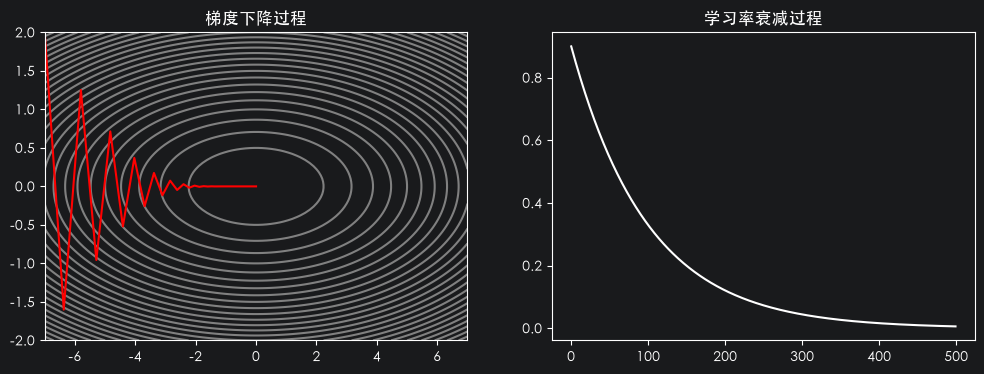

In [42]:
plt.rcParams['font.sans-serif'] = ['STHeiti']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
# 等高线
w1, w2 = np.meshgrid(np.linspace(-7, 7, 100), np.linspace(-2, 2, 100))
loss = loss_fn([w1, w2])
ax[0].contour(w1, w2, loss, colors='gray', levels=30)
ax[0].plot(w1_history, w2_history, color='r')
ax[0].set_title("梯度下降过程")
ax[1].plot(lr_history, color='w')
ax[1].set_title("学习率衰减过程")
plt.show()